In [6]:
import numpy as np
import napari

# load raw binary (example float32)
vol = np.fromfile(r"C:\CODE\MRPNN-main\build\TestCase\MODEL1.bin", dtype=np.float32, offset=4)

# reshape to your known dimensions
vol = vol.reshape((1024, 1024, 1024))
vol_x = np.swapaxes(vol, 0, 1)  # swap Z and X

viewer = napari.Viewer();
viewer.add_image(vol_x, rendering='attenuated_mip', contrast_limits=(-255, 255))
#napari.view_image(vol, rendering='attenuated_mip')

napari.run()

In [2]:
print("hey")

hey


In [1]:
def lerp(a, b, t):
    return a + t * (b - a)

result = 0;
result2 = 0;
for i in range(25):
    result = lerp(result, i, 1.0/(1.0+i))
    result2 += i;
result2 /= 25;
print(result)
print(result2)

12.0
12.0


In [ ]:
.\.venv_312\Scripts\python.exe -c "import sys; print(sys.executable, sys.version)"

In [6]:
import sys, pathlib, os
print("Kernel Python:", sys.executable, sys.version)

import torch
from pathlib import Path
import os

torch_lib_dir = Path(torch.__file__).parent / "lib"
os.add_dll_directory(str(torch_lib_dir))

import mrpnn_input_data_extension
print("Extension OK:", mrpnn_input_data_extension)

Kernel Python: C:\CODE\MRPNN-main\training_pipeline\.venv_cp312\Scripts\python.exe 3.12.9 (tags/v3.12.9:fdb8142, Feb  4 2025, 15:27:58) [MSC v.1942 64 bit (AMD64)]
Extension OK: <module 'mrpnn_input_data_extension' from 'C:\\CODE\\MRPNN-main\\training_pipeline\\mrpnn_input_data_extension.pyd'>


In [4]:
import numpy as np
import torch


# 1. Describe expected shapes: name -> (To, From) or ("bias", To)
EXPECTED_SHAPES = {
    # -------------------------------------------------------
    # SE Gating (8 → 8) and (8 → 3)
    # -------------------------------------------------------
    "LSE01W": ("W", 8, 8),  "LSE02W": ("W", 8, 3),
    "LSE11W": ("W", 8, 8),  "LSE12W": ("W", 8, 3),
    "LSE21W": ("W", 8, 8),  "LSE22W": ("W", 8, 3),
    "LSE31W": ("W", 8, 8),  "LSE32W": ("W", 8, 3),
    "LSE41W": ("W", 8, 8),  "LSE42W": ("W", 8, 3),
    "LSE51W": ("W", 8, 8),  "LSE52W": ("W", 8, 3),
    "LSE61W": ("W", 8, 8),  "LSE62W": ("W", 8, 3),
    "LSE71W": ("W", 8, 8),  "LSE72W": ("W", 8, 3),

    # -------------------------------------------------------
    # Phase 1 – Main Branch Blocks L01..L71
    # -------------------------------------------------------
    "L01W": ("W", 8, 8),   "L01B": ("B", 8),
    "L11W": ("W", 8, 8),   "L11B": ("B", 8),
    "L21W": ("W",16,16),   "L21B": ("B",16),
    "L31W": ("W",16,16),   "L31B": ("B",16),
    "L41W": ("W",16,16),   "L41B": ("B",16),
    "L51W": ("W",32,32),   "L51B": ("B",32),
    "L61W": ("W",32,32),   "L61B": ("B",32),
    "L71W": ("W",32,32),   "L71B": ("B",32),

    # Tr branches
    "L_Tr01W": ("W", 8,8),  "L_Tr01B": ("B",8),
    "L_Tr11W": ("W", 8,8),  "L_Tr11B": ("B",8),
    "L_Tr21W": ("W",16,16), "L_Tr21B": ("B",16),
    "L_Tr31W": ("W",16,16), "L_Tr31B": ("B",16),
    "L_Tr41W": ("W",16,16), "L_Tr41B": ("B",16),
    "L_Tr51W": ("W",32,32), "L_Tr51B": ("B",32),
    "L_Tr61W": ("W",32,32), "L_Tr61B": ("B",32),
    "L_Tr71W": ("W",32,32), "L_Tr71B": ("B",32),

    # Hg branches
    "L_Hg01W": ("W", 8,8),  "L_Hg01B": ("B",8),
    "L_Hg11W": ("W", 8,8),  "L_Hg11B": ("B",8),
    "L_Hg21W": ("W",16,16), "L_Hg21B": ("B",16),
    "L_Hg31W": ("W",16,16), "L_Hg31B": ("B",16),
    "L_Hg41W": ("W",16,16), "L_Hg41B": ("B",16),
    "L_Hg51W": ("W",32,32), "L_Hg51B": ("B",32),
    "L_Hg61W": ("W",32,32), "L_Hg61B": ("B",32),
    "L_Hg71W": ("W",32,32), "L_Hg71B": ("B",32),

    # -------------------------------------------------------
    # Final Phase-1 Projection (L8)
    # -------------------------------------------------------
    "L81W": ("W",32,32),     "L81B": ("B",32),
    "L_Tr81W": ("W",32,32),  "L_Tr81B": ("B",32),
    "L_Hg81W": ("W",32,32),  "L_Hg81B": ("B",32),

    # -------------------------------------------------------
    # Directional Phase (LD Blocks)
    # -------------------------------------------------------
    # LD0..LD3 (all 8 → 8)
    "LD01W": ("W",8,8), "LD01B": ("B",8),
    "LD11W": ("W",8,8), "LD11B": ("B",8),
    "LD21W": ("W",8,8), "LD21B": ("B",8),
    "LD31W": ("W",8,8), "LD31B": ("B",8),

    # Tr branches
    "LD_Tr01W": ("W",8,8), "LD_Tr01B": ("B",8),
    "LD_Tr11W": ("W",8,8), "LD_Tr11B": ("B",8),
    "LD_Tr21W": ("W",8,8), "LD_Tr21B": ("B",8),
    "LD_Tr31W": ("W",8,8), "LD_Tr31B": ("B",8),

    # Hg branches
    "LD_Hg01W": ("W",8,8), "LD_Hg01B": ("B",8),
    "LD_Hg11W": ("W",8,8), "LD_Hg11B": ("B",8),
    "LD_Hg21W": ("W",8,8), "LD_Hg21B": ("B",8),
    "LD_Hg31W": ("W",8,8), "LD_Hg31B": ("B",8),

    # LD Gating
    "LDSE01W": ("W",8,8), "LDSE02W": ("W",8,3),
    "LDSE11W": ("W",8,8), "LDSE12W": ("W",8,3),
    "LDSE21W": ("W",8,8), "LDSE22W": ("W",8,3),
    "LDSE31W": ("W",8,8), "LDSE32W": ("W",8,3),

    # Final LD projection
    "LD41W": ("W",8,8),     "LD41B": ("B",8),
    "LD_Tr41W": ("W",8,8),  "LD_Tr41B": ("B",8),
    "LD_Hg41W": ("W",8,8),  "LD_Hg41B": ("B",8),

    # -------------------------------------------------------
    # Tail (SC Macro)
    # -------------------------------------------------------

    # SC projection of [g, gamma, scbase] → 8
    "LGGSW": ("W",3,8),  "LGGSB": ("B",8),

    # SC gating (75 → 16 → 6)
    "LSEFin1W": ("W",75,16),
    "LSEFin2W": ("W",16,6),

    # Tail MLP
    "LC0W": ("W",128,128), "LC0B": ("B",128),
    "LC1W": ("W",128,64),  "LC1B": ("B",64),
    "LC2W": ("W",64,32),   "LC2B": ("B",32),
    "LXW":  ("W",32,16),   "LXB":  ("B",16),

    # 12 Residual Blocks (LX0..LX11)
    "LX0W": ("W",16,16), "LX0B": ("B",16),
    "LX1W": ("W",16,16), "LX1B": ("B",16),
    "LX2W": ("W",16,16), "LX2B": ("B",16),
    "LX3W": ("W",16,16), "LX3B": ("B",16),
    "LX4W": ("W",16,16), "LX4B": ("B",16),
    "LX5W": ("W",16,16), "LX5B": ("B",16),
    "LX6W": ("W",16,16), "LX6B": ("B",16),
    "LX7W": ("W",16,16), "LX7B": ("B",16),
    "LX8W": ("W",16,16), "LX8B": ("B",16),
    "LX9W": ("W",16,16), "LX9B": ("B",16),
    "LX10W": ("W",16,16), "LX10B": ("B",16),
    "LX11W": ("W",16,16), "LX11B": ("B",16),

    # Final Tail Output (16 → 1)
    "LX12W": ("W",16,1),   "LX12B": ("B",1),
}

def load_npy_as_dict(path: str):
    raw = np.load(path, allow_pickle=True)
    if isinstance(raw, np.ndarray) and raw.shape == () and raw.dtype == object:
        data = raw.item()
        if not isinstance(data, dict):
            raise TypeError(f"{path} contained object but not a dict")
        return data
    elif isinstance(raw, dict):
        return raw
    else:
        raise TypeError(
            f"{path} has unexpected type/shape: type={type(raw)}, shape={getattr(raw, 'shape', None)}"
        )


def check_weights_compatibility(path: str):
    weights_np = load_npy_as_dict(path)

    print(f"Loaded {len(weights_np)} entries from {path}")

    # 1) Check for missing / extra keys
    expected_keys = set(EXPECTED_SHAPES.keys())
    actual_keys = set(weights_np.keys())

    missing = expected_keys - actual_keys
    extra   = actual_keys - expected_keys

    if missing:
        print("⚠ Missing keys in npy:", sorted(missing))
    else:
        print("✅ No missing keys.")

    if extra:
        print("ℹ Extra keys in npy (not used by RadiancePredictorExact):", sorted(extra))

    # 2) Check shapes / lengths
    all_ok = True
    for name, (kind, to_dim, *rest) in EXPECTED_SHAPES.items():
        from_dim = rest[0] if rest else None

        if name not in weights_np:
            all_ok = False
            continue

        arr = np.asarray(weights_np[name])
        numel = arr.size

        if kind == "W":
            expected_numel = to_dim * from_dim
            if numel != expected_numel:
                print(f"❌ {name}: expected {expected_numel} elements ({to_dim}x{from_dim}), got {numel}")
                all_ok = False
            else:
                print(f"✅ {name}: ok numel={numel} ({to_dim}x{from_dim})")
        elif kind == "B":
            expected_numel = to_dim
            if numel != expected_numel:
                print(f"❌ {name}: expected {expected_numel} elements (bias), got {numel}")
                all_ok = False
            else:
                print(f"✅ {name}: ok numel={numel} (bias)")
        else:
            raise ValueError(f"Unknown kind {kind} for {name}")

    if all_ok:
        print("\n🎉 All checked weights are compatible with RadiancePredictorExact.")
    else:
        print("\n⚠ Some weights are incompatible – fix those before using them.")


if __name__ == "__main__":
    check_weights_compatibility("NNWeight.npy")


Loaded 146 entries from NNWeight.npy
✅ No missing keys.
✅ LSE01W: ok numel=64 (8x8)
✅ LSE02W: ok numel=24 (8x3)
✅ LSE11W: ok numel=64 (8x8)
✅ LSE12W: ok numel=24 (8x3)
✅ LSE21W: ok numel=64 (8x8)
✅ LSE22W: ok numel=24 (8x3)
✅ LSE31W: ok numel=64 (8x8)
✅ LSE32W: ok numel=24 (8x3)
✅ LSE41W: ok numel=64 (8x8)
✅ LSE42W: ok numel=24 (8x3)
✅ LSE51W: ok numel=64 (8x8)
✅ LSE52W: ok numel=24 (8x3)
✅ LSE61W: ok numel=64 (8x8)
✅ LSE62W: ok numel=24 (8x3)
✅ LSE71W: ok numel=64 (8x8)
✅ LSE72W: ok numel=24 (8x3)
✅ L01W: ok numel=64 (8x8)
✅ L01B: ok numel=8 (bias)
✅ L11W: ok numel=64 (8x8)
✅ L11B: ok numel=8 (bias)
✅ L21W: ok numel=256 (16x16)
✅ L21B: ok numel=16 (bias)
✅ L31W: ok numel=256 (16x16)
✅ L31B: ok numel=16 (bias)
✅ L41W: ok numel=256 (16x16)
✅ L41B: ok numel=16 (bias)
✅ L51W: ok numel=1024 (32x32)
✅ L51B: ok numel=32 (bias)
✅ L61W: ok numel=1024 (32x32)
✅ L61B: ok numel=32 (bias)
✅ L71W: ok numel=1024 (32x32)
✅ L71B: ok numel=32 (bias)
✅ L_Tr01W: ok numel=64 (8x8)
✅ L_Tr01B: ok numel=8 (b

In [1]:
import torch
from pathlib import Path
import matplotlib.pyplot as plt
import mrpnn_helpers
from radiance_predictor_exact import RadiancePredictorExact

device = torch.device("cuda")

# 1) Build the predictor from weights
weights_np   = mrpnn_helpers.load_npy_as_dict("NNWeight.npy")
weight_dict  = mrpnn_helpers.build_weight_dict(weights_np)
predictor    = RadiancePredictorExact(weight_dict, device=device).eval()

# 2) Wrap with the C++ data fetcher
width, height = 1024, 1024  # or whatever your C++ extension uses
wrapper = mrpnn_helpers.MRPNNWrapper(predictor, width, height, device=device)

# 3) Define g and scatterrate (global for this frame)
g_value = 0.857
scatter = (1.0, 1.0, 1.0)   # example isotropic; use your actual triplet

# 4) Run inference
image = wrapper(g_value, scatter)  # (H, W, 3) on CUDA

# 5) Bring to CPU and visualize (do any tonemapping you like)
img_vis = image.detach().cpu()

# simple normalization / clamp for display
img_min = img_vis.min()
img_max = img_vis.max()
img_norm = (img_vis - img_min) / (img_max - img_min + 1e-8)
img_np = img_norm.numpy()

plt.figure(figsize=(10, 6))
plt.imshow(img_np)
plt.axis("off")
plt.show()


577


RuntimeError: mat1 and mat2 shapes cannot be multiplied (1048576x8 and 3x8)

In [2]:
import torch
print(torch. __version__)

2.7.1+cu118


In [ ]:
import torch
import mrpnn_input_data_extension as ext

rp = ext.MRPNNInputData(width=64, height=64)
out = rp.fetch_input()      # small size first
print(out.shape, out.device)


module://matplotlib_inline.backend_inline


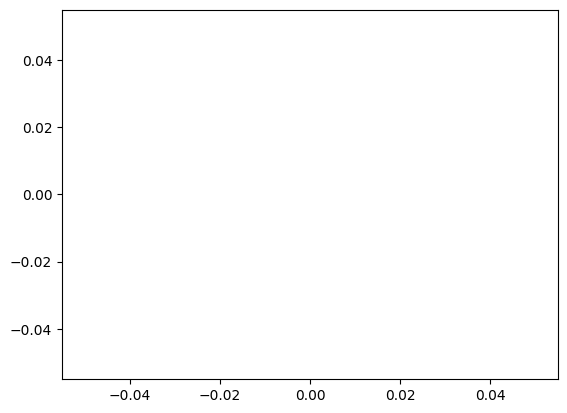

In [5]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
print(matplotlib.get_backend())

plt.ion()
fig, ax = plt.subplots()
line, = ax.plot([], [])
plt.show(block=False)

y = []
for i in range(200):
    y.append(np.exp(-i/50) + 0.01)
    x = np.arange(len(y))
    line.set_data(x, y)
    ax.set_xlim(0, max(10, len(x)))
    ax.set_ylim(1e-4, 2)
    fig.canvas.draw_idle()
    fig.canvas.flush_events()
    plt.pause(0.05)


In [29]:
import math

p0 = 0.63984829
passtrough = 0.5
S = 1
SMax = 1
t_step = 1
result = t_step*math.log(0.5/p0)/math.log(passtrough + (1.0 - passtrough)*(1.0 - S / SMax))
print(result)

t_step = 3.0 / 1024
SMax = 64
pass_rate = math.exp(-t_step * SMax)
print(pass_rate)

res = 180 / math.pi * math.asin(math.sqrt(2*math.pi/(math.sqrt(3)*32)))
print(res)

print(math.acos(-1.0))

0.35580178333445006
0.8290291181804004
19.675546992964303
3.141592653589793
